# 1.0 Exploración de los datos de MiBici

**Equipo 34 - TC5061** · Notebook solo de exploración: la lógica final vive en el módulo `mibici`
(`dataset.py` para la ingesta y `features.py` para las variables).

Requiere haber ejecutado `python -m mibici.dataset ingest` y `python -m mibici.features`.

Objetivos:
1. Dimensionar los datos limpios (meses, viajes, estaciones).
2. Revisar la estacionalidad semanal, horaria y anual que justifica las variables de calendario y los lags.
3. Calibrar la aproximación del riesgo de P2 (flujo neto vs. capacidad).
4. Observar patrones de uso por estación que motivan el clustering de P3.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici.config import DATA_MANIFEST_PATH, P1_DATASET_PATH, P2_DATASET_PATH
from mibici.dataset import load_stations, load_trips
from mibici.features import risk_label

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

2026-10-13 18:13:49.823 | INFO     | mibici.config:<module>:19 - PROJ_ROOT path is: C:\Users\diego\projects\TC5061-Proyecto-Equipo34


## 1. Tamaño de los datos y versión

In [2]:
manifest = json.loads(DATA_MANIFEST_PATH.read_text(encoding="utf-8"))
print("data_version:", manifest["data_version"])
pd.Series(manifest["totals"])

data_version: efa3a16661ec


months                       32
trips_raw              12049962
trips_clean            11677716
stations_catalog            484
stations_with_trips         473
dtype: int64

In [3]:
files = pd.DataFrame([f for f in manifest["files"] if f["kind"] == "trips"])
files[["month", "encoding", "rows_raw", "rows_clean", "dropped_duration"]].assign(
    pct_descartado=lambda d: (100 * (1 - d.rows_clean / d.rows_raw)).round(2)
)

,month,encoding,rows_raw,rows_clean,dropped_duration,pct_descartado
0,2024-01,latin-1,391591,376673,14918,3.81
1,2024-02,latin-1,383732,369060,14672,3.82
2,2024-03,latin-1,390513,375237,15276,3.91
3,2024-04,latin-1,405308,389326,15982,3.94
4,2024-05,latin-1,410806,395794,15012,3.65
5,2024-06,latin-1,365000,354102,10898,2.99
6,2024-07,utf-8,364177,352603,11574,3.18
7,2024-08,latin-1,394894,383125,11769,2.98
8,2024-09,latin-1,390072,382496,7576,1.94
9,2024-10,latin-1,418690,410559,8131,1.94


La codificación cambia entre meses (Latin-1 en 2024 y parte de 2025, UTF-8 después) y el encabezado de
2024-02 viene corrupto; la ingesta lo resuelve detectando la codificación y mapeando columnas por palabra clave.
Alrededor del 3 % de los viajes se descarta por duración fuera de 1-180 minutos.

In [4]:
trips = load_trips()
stations = load_stations()
print(f"{len(trips):,} viajes | {trips.origen_id.nunique()} estaciones de origen | {len(stations)} en catálogo")
trips.head()

11,677,716 viajes | 473 estaciones de origen | 484 en catálogo


,viaje_id,inicio_viaje,fin_viaje,origen_id,destino_id,duracion_min
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,24.200001
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,9.233334
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,9.100000
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,23.916666
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,23.700001


In [5]:
stations.describe()[["capacity", "latitude", "longitude"]]

,capacity,latitude,longitude
count,484.000000,484.000000,484.000000
mean,16.882231,20.678520,-103.361871
std,4.126942,0.022032,0.031626
min,0.000000,20.636130,-103.433215
25%,15.000000,20.665077,-103.384164
50%,15.000000,20.674390,-103.362443
75%,19.000000,20.688609,-103.339320
max,39.000000,20.739523,-103.297112


## 2. Estacionalidad

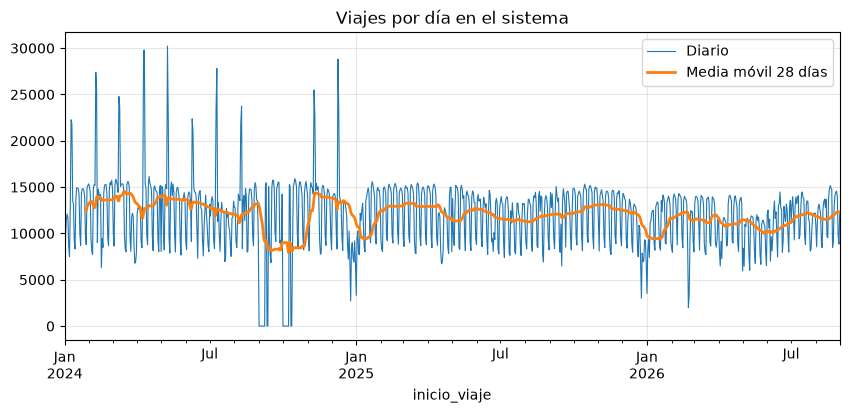

In [6]:
daily = trips.set_index("inicio_viaje").resample("D").size()
ax = daily.plot(lw=0.8, label="Diario")
daily.rolling(28).mean().plot(ax=ax, lw=2, label="Media móvil 28 días")
ax.set_title("Viajes por día en el sistema")
ax.legend();

Se aprecian caídas en vacaciones de Semana Santa y diciembre y un nivel estable en el resto del año, por lo que
las variables de mes y festivo son pertinentes para P1.

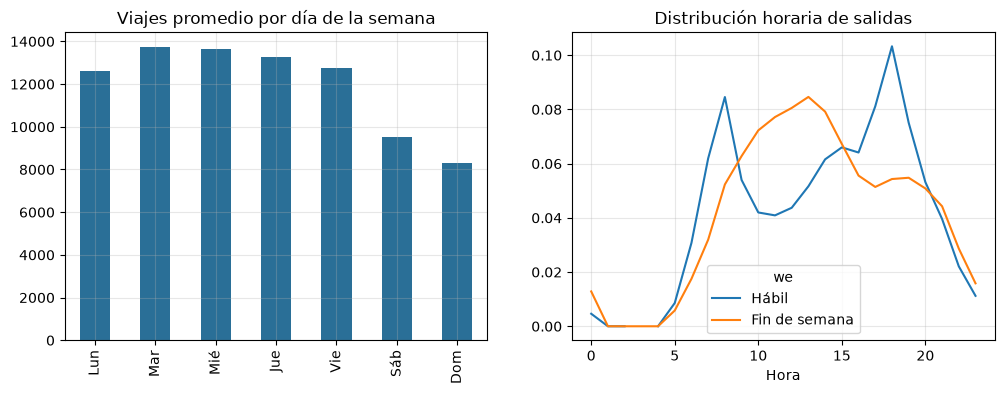

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dow_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
(daily.groupby(daily.index.dayofweek).mean().set_axis(dow_names)
    .plot.bar(ax=axes[0], color="#2a6f97", title="Viajes promedio por día de la semana"))
hourly = trips.assign(h=trips.inicio_viaje.dt.hour, we=trips.inicio_viaje.dt.dayofweek >= 5)
(hourly.groupby(["h", "we"]).size().unstack().div(hourly.groupby("we").size())
    .rename(columns={False: "Hábil", True: "Fin de semana"})
    .plot(ax=axes[1], title="Distribución horaria de salidas"))
axes[1].set_xlabel("Hora");

Entre semana hay dos picos (07-09 h y 18-19 h) asociados a traslados laborales; el fin de semana el uso se
concentra a media mañana. Esto motiva: (a) lags de 7 días en P1, (b) bloques de 3 horas en P2 y (c) perfiles
horarios separados por tipo de día en P3.

## 3. Demanda por estación (P1)

In [8]:
p1 = pd.read_parquet(P1_DATASET_PATH)
print(p1.groupby("split").agg(filas=("departures", "size"), estaciones=("station_id", "nunique"),
                            desde=("date", "min"), hasta=("date", "max"), media=("departures", "mean")))
p1.departures.describe()

        filas  estaciones      desde      hasta      media
split                                                     
test    50561         471 2026-05-01 2026-08-31  27.273788
train  262712         373 2024-01-15 2025-12-31  33.298410
valid   44760         373 2026-01-01 2026-04-30  30.654446


count    358033.000000
mean         32.117081
std          34.498951
min           0.000000
25%          10.000000
50%          22.000000
75%          43.000000
max         634.000000
Name: departures, dtype: float64

Correlación lag7: 0.862


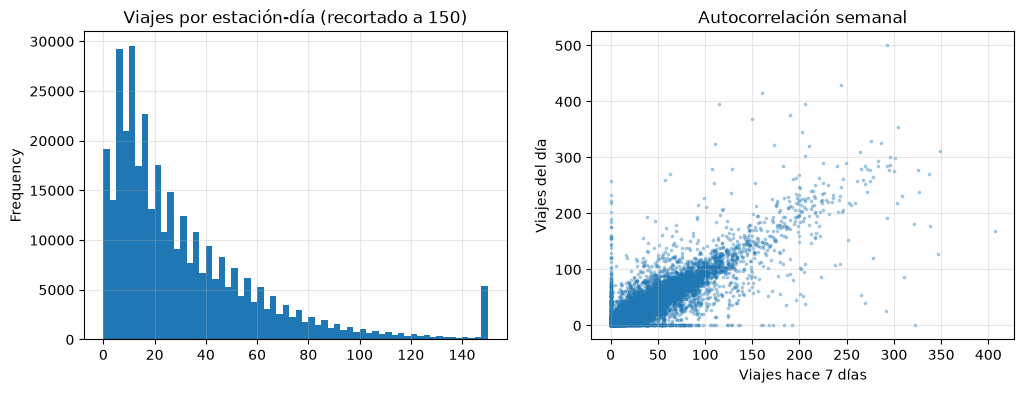

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p1.departures.clip(upper=150).plot.hist(bins=60, ax=axes[0], title="Viajes por estación-día (recortado a 150)")
sample = p1.sample(20000, random_state=42)
axes[1].scatter(sample.departures_lag7, sample.departures, s=3, alpha=0.3)
axes[1].set(xlabel="Viajes hace 7 días", ylabel="Viajes del día", title="Autocorrelación semanal")
print("Correlación lag7:", p1[["departures", "departures_lag7"]].corr().iloc[0, 1].round(3))

La distribución es asimétrica (conteos con muchas estaciones de baja demanda), lo que justifica la pérdida
Poisson en el modelo candidato y reportar MAE y WAPE además de RMSE. La correlación con el mismo día de la semana
anterior es alta, por eso el baseline es un *naive* estacional de 7 días.

<Axes: title={'center': 'Estaciones por mes de primer viaje'}, xlabel='date'>

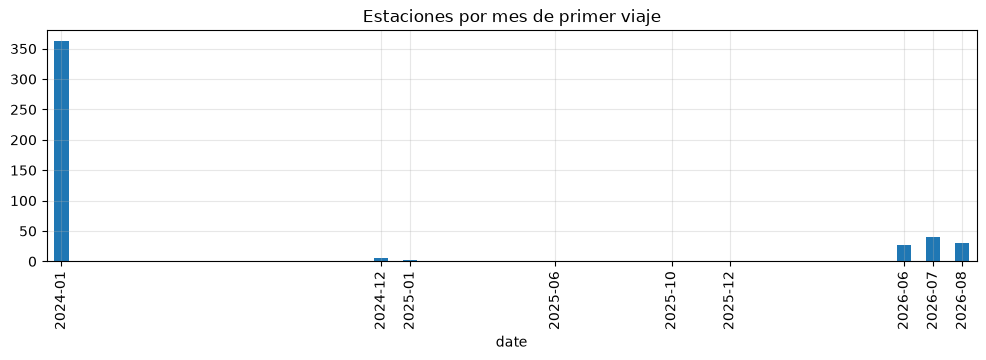

In [10]:
opened = p1.groupby("station_id").date.min()
opened.dt.to_period("M").value_counts().sort_index().plot.bar(figsize=(12, 3), title="Estaciones por mes de primer viaje")

Alrededor de 100 estaciones nuevas empezaron a operar en 2026 (periodo de validación y prueba). El modelo
de P1 debe generalizar a estaciones sin historia larga; por eso las variables usan solo lags cortos (1-28 días)
y atributos de la estación, no un identificador de estación.

## 4. Aproximación del riesgo de P2

In [11]:
p2 = pd.read_parquet(P2_DATASET_PATH)
p2.groupby("split")[["risk", "risk_empty", "risk_full"]].mean().round(4)

,risk,risk_empty,risk_full
split,,,
test,0.0252,0.0106,0.0146
train,0.0500,0.0272,0.0228
valid,0.0333,0.0142,0.0192


In [12]:
fractions = [0.3, 0.4, 0.5, 0.6, 0.75]
prevalence = {f: risk_label(p2.net_flow, p2.capacity * f / 0.5)["risk"].mean() for f in fractions}
pd.Series(prevalence, name="prevalencia").rename_axis("fracción de capacidad")

fracción de capacidad
0.30    0.138285
0.40    0.083827
0.50    0.044382
0.60    0.028462
0.75    0.011144
Name: prevalencia, dtype: float64

Con un umbral de 0.5 x capacidad, ~5 % de los bloques de entrenamiento quedan en riesgo: es un evento poco
frecuente pero no extremo, con suficientes positivos para entrenar. Umbrales menores marcarían como riesgo
desbalances que el sistema absorbe normalmente; mayores dejarían muy pocos casos. Como la clase positiva es
minoritaria, las métricas principales serán PR-AUC, recall y F1 (no exactitud).

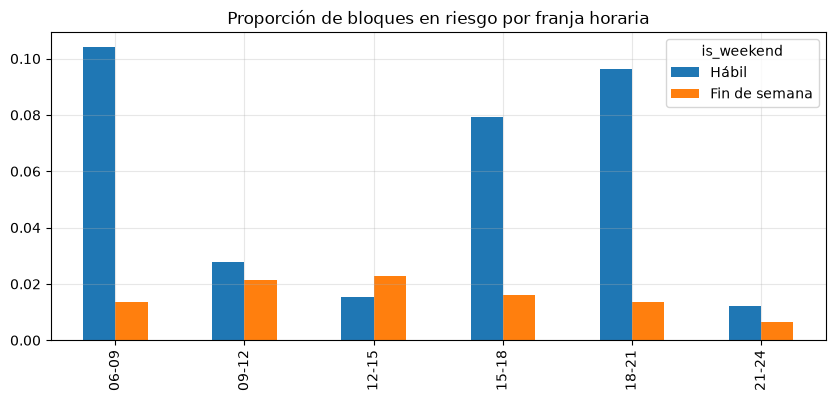

In [13]:
(p2.groupby(["block", "is_weekend"]).risk.mean().unstack()
   .rename(columns={0: "Hábil", 1: "Fin de semana"})
   .set_axis(["06-09", "09-12", "12-15", "15-18", "18-21", "21-24"])
   .plot.bar(title="Proporción de bloques en riesgo por franja horaria"));

El riesgo se concentra en las horas pico (mañana y tarde), coherente con los traslados pendulares: unas
estaciones se vacían en la mañana y otras se llenan, y se invierte en la tarde.

## 5. Patrones de uso por estación (P3)

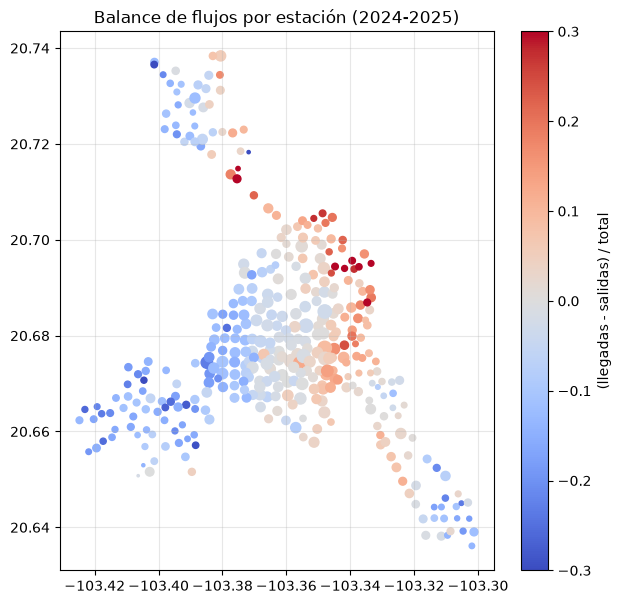

In [14]:
train = trips[trips.inicio_viaje < "2026-01-01"]
by_station = train.groupby("origen_id").agg(salidas=("viaje_id", "size"))
by_station["llegadas"] = train.groupby("destino_id").size()
by_station["balance"] = (by_station.llegadas - by_station.salidas) / (by_station.llegadas + by_station.salidas)
geo = stations.set_index("station_id").join(by_station, how="inner")
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(geo.longitude, geo.latitude, c=geo.balance, cmap="coolwarm", vmin=-0.3, vmax=0.3,
                s=np.sqrt(geo.salidas) / 4)
plt.colorbar(sc, label="(llegadas - salidas) / total")
ax.set_title("Balance de flujos por estación (2024-2025)");

Existen estaciones que reciben sistemáticamente más bicicletas de las que despachan (y viceversa) y una
fuerte variación de volumen entre estaciones. Junto con el perfil horario, estas variables forman el vector de
cada estación para el clustering de P3.

## Conclusiones para el pipeline
- Partición temporal: train 2024-01 a 2025-12, validación 2026-01 a 2026-04, prueba 2026-05 a 2026-08.
- P1: objetivo de conteos asimétricos; baseline naive de 7 días; lags y calendario como variables.
- P2: etiqueta derivada del flujo neto por bloque de 3 h (~5 % positivos); métricas para clases desbalanceadas.
- P3: perfiles horarios hábil/fin de semana + volumen + balance; fit solo con train.